# The systematic risk of Brazilian stocks, one by one

The previous notebooks decompose the risk of portfolios. This one does it for each stock of the investable universe of the companion repository (stocks of the SMLL and MLCX indices with a median traded value above R$ 1 million over 42 days, one ticker per company), year by year.

For each calendar year from 2010 to 2025, each stock with at least 200 daily returns inside the universe is regressed on the seven local factors, orthogonalized on the days of that stock, so its decomposed $R^2$ add up exactly to its $R^2$. The averages weight the stocks equally, or by their market value on the first trading day of the year. 2026 is left out because it has only 139 trading days so far.

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from orthofactors.data import load_brazil_factors, load_brazil_stocks, BRAZIL_FACTORS
from orthofactors.decomposition import decompose
from orthofactors.plotting import set_style, plot_decomposition_bars, IDIOSYNCRATIC

set_style()
Path('results').mkdir(exist_ok = True)
components = BRAZIL_FACTORS + ['idiosyncratic']

In [2]:
factors = load_brazil_factors()[BRAZIL_FACTORS]
stock_returns, stock_weights = load_brazil_stocks()

rows = []
for year in range(2010, 2026):
    returns = stock_returns.loc[str(year)]
    eligible = returns.columns[returns.count() >= 200]
    for ticker in eligible:
        result, dr2 = decompose(returns[ticker], factors.loc[str(year)])
        rows.append({'Year': year, 'Ticker': ticker, **dr2, 'idiosyncratic': 1 - result.rsquared, 'Days': int(result.nobs)})
stocks = pd.DataFrame(rows)
assert np.allclose(stocks[components].sum(axis = 1), 1)

# Relative market value on the first trading day of the year, rescaled to add up to 1 among the stocks of the year
weights = stock_weights.rename_axis(columns = 'Ticker').stack().rename('Weight').reset_index()
weights['Year'] = weights['Date'].dt.year
stocks = stocks.merge(weights[['Year', 'Ticker', 'Weight']], on = ['Year', 'Ticker'], how = 'left')
stocks['Weight'] = stocks['Weight'] / stocks.groupby('Year')['Weight'].transform('sum')

stocks.groupby('Year').agg(Stocks = ('Ticker', 'count'), Median_days = ('Days', 'median'),
                           Weight_covered = ('Weight', lambda w: w.notna().mean())).T

Year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Stocks,105.000000,97.000000,119.000000,123.00000,117.000000,106.000000,104.000000,102.0,116.000000,120.000000,130.000000,143.000000,184.000000,166.0,158.0,150.000000
Median_days,250.000000,251.000000,251.000000,253.00000,253.000000,250.000000,251.000000,249.0,250.000000,253.000000,251.000000,251.000000,251.000000,249.0,253.0,252.000000
Weight_covered,0.971429,0.989691,0.957983,0.95122,0.931624,0.981132,0.971154,1.0,0.982759,0.966667,0.923077,0.993007,0.983696,1.0,1.0,0.966667


## The average stock

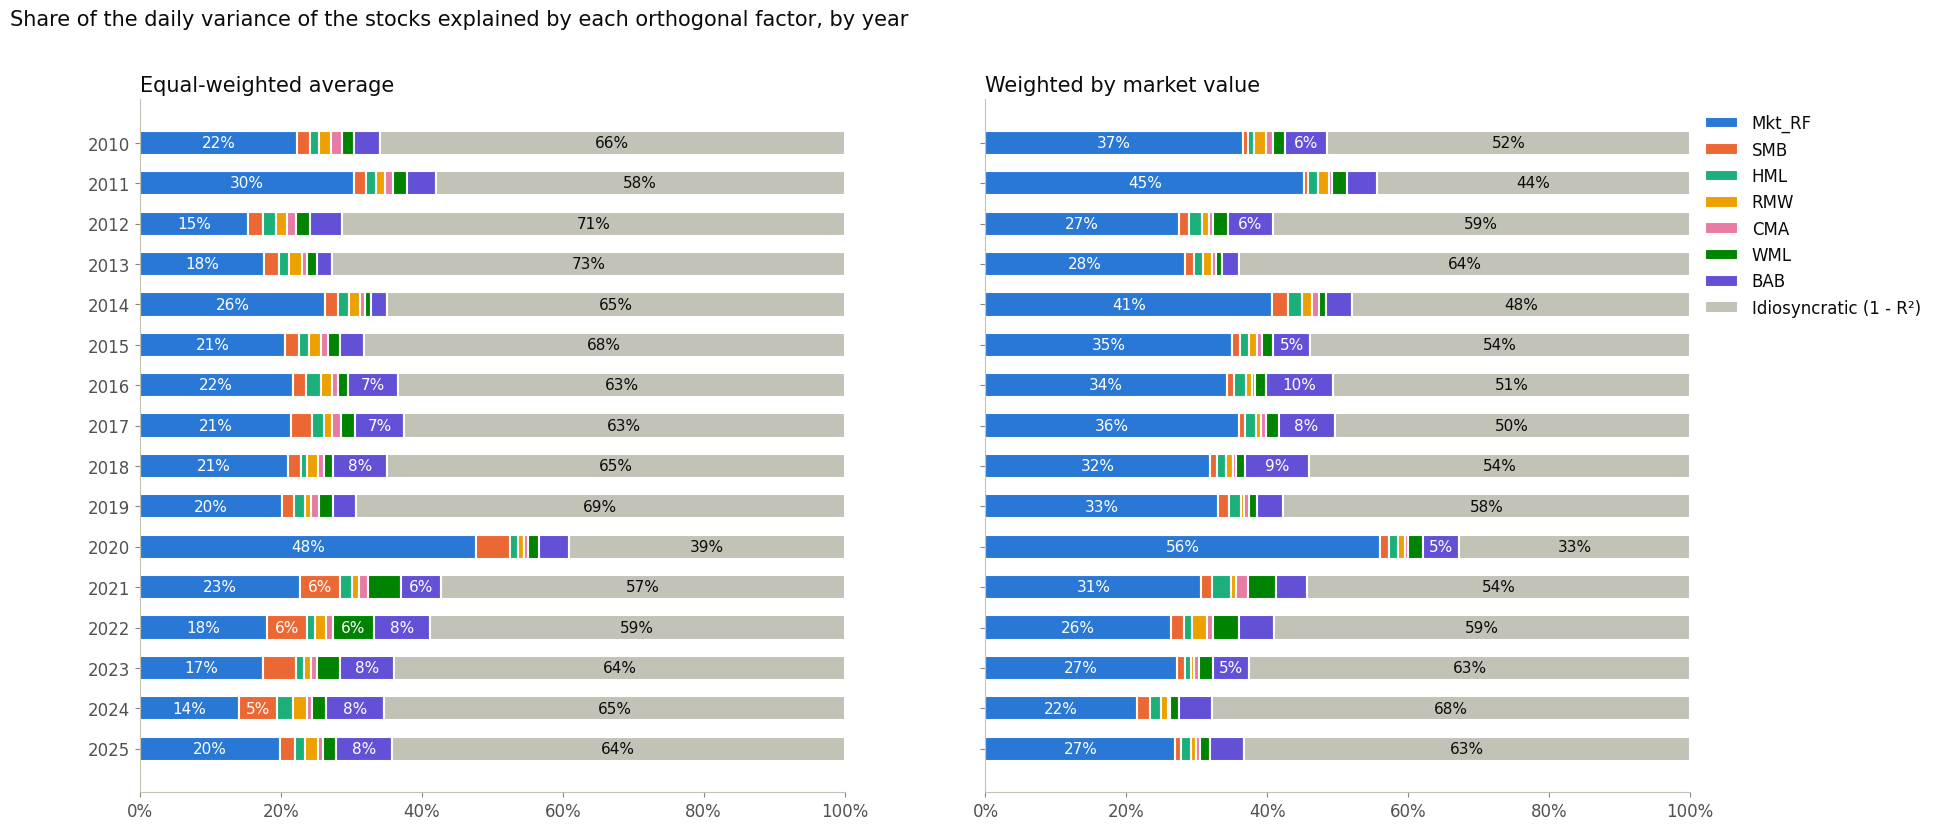

In [3]:
equal = stocks.groupby('Year')[components].mean()
value = stocks.dropna(subset = ['Weight']).groupby('Year')[components + ['Weight']].apply(
    lambda g: g[components].mul(g['Weight'], axis = 0).sum() / g['Weight'].sum())

fig, axes = plt.subplots(1, 2, figsize = (20, 9))
plot_decomposition_bars(axes[0], equal, BRAZIL_FACTORS, 'Equal-weighted average', label_min = 0.05)
plot_decomposition_bars(axes[1], value, BRAZIL_FACTORS, 'Weighted by market value', label_min = 0.05)
axes[0].get_legend().remove()
axes[1].set_yticklabels([])
fig.suptitle('Share of the daily variance of the stocks explained by each orthogonal factor, by year', x = 0.06, ha = 'left', fontsize = 15)
plt.show()

In [4]:
pd.concat({'Equal-weighted': equal, 'Weighted by market value': value}, axis = 1).style.format('{:.1%}')

In [5]:
# Over all the stock-years
pd.DataFrame({'Equal-weighted': stocks[components].mean(),
              'Weighted by market value': value.mean(),
              'Median': stocks[components].median()}).T.style.format('{:.1%}')

,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
Equal-weighted,21.9%,3.3%,1.5%,1.4%,1.0%,2.4%,5.7%,62.9%
Weighted by market value,33.6%,1.3%,1.5%,1.1%,0.7%,1.8%,5.4%,54.6%
Median,19.1%,1.6%,0.8%,0.7%,0.5%,1.1%,3.3%,64.7%


For the typical stock, the seven factors explain about a third of the daily variance. Over all the stock-years, the market explains 22%, BAB 6%, size 3% and the other four factors 6% together, and 63% is idiosyncratic. Weighted by market value, the market explains more, 34%, because the large companies dominate the Ibovespa and move with it.

In 2020 the COVID-19 crash moved almost all stocks together, and the share of the market in the average stock more than doubled, from 20% in 2019 to 48%. As in the strategies, BAB matters more in recent years: it explains 2% to 5% of the average stock until 2015, and 7% or 8% in 2016 to 2018 and 2022 to 2025.

## How different the stocks are

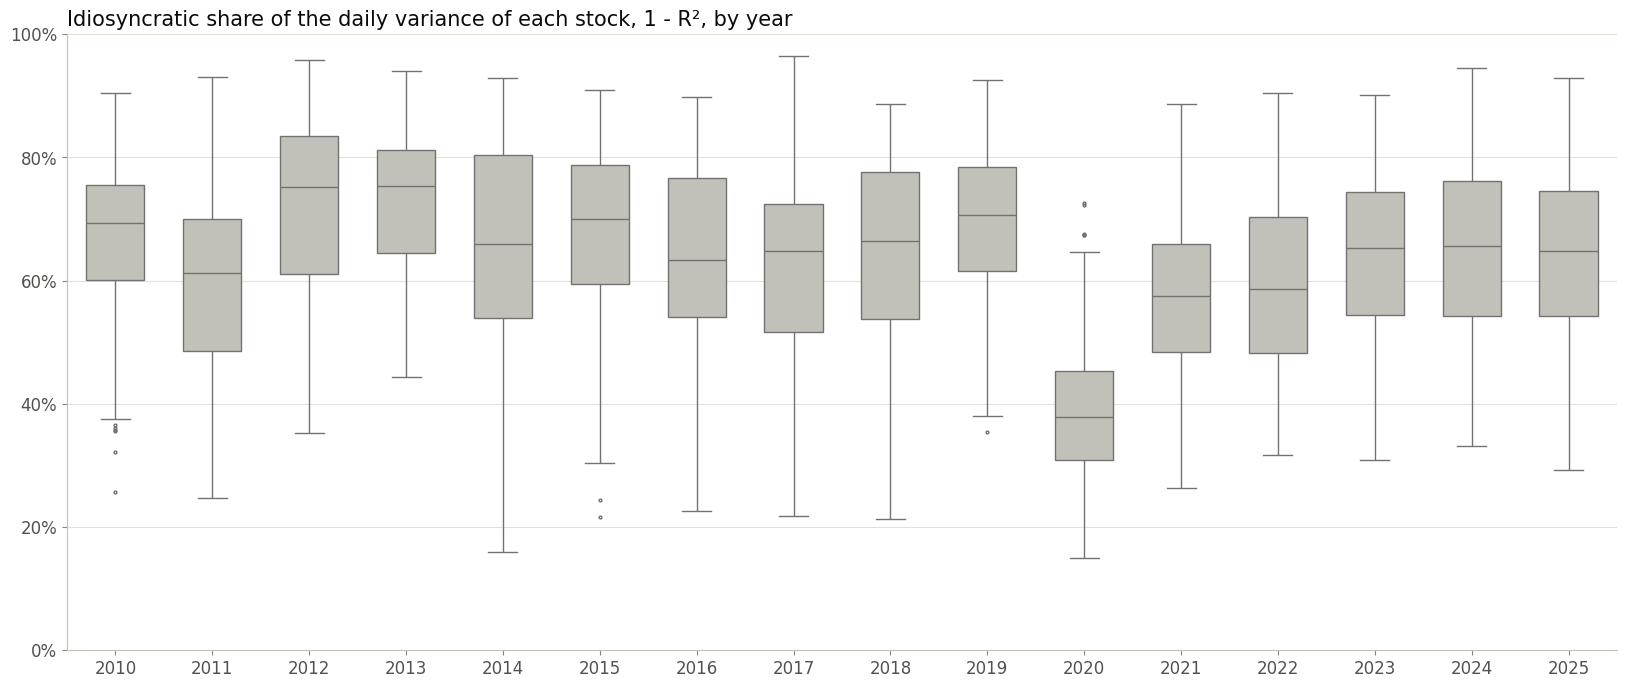

In [6]:
fig, ax = plt.subplots()
sns.boxplot(data = stocks, x = 'Year', y = 'idiosyncratic', color = IDIOSYNCRATIC, width = 0.6, fliersize = 2, ax = ax)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylim(0, 1)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title('Idiosyncratic share of the daily variance of each stock, 1 - R², by year')
plt.show()

In [7]:
# Stocks with the largest and the smallest average idiosyncratic share, among those in the sample for at least 8 years
by_stock = stocks.groupby('Ticker').agg(Years = ('Year', 'count'), Idiosyncratic = ('idiosyncratic', 'mean'),
                                        Market = ('Mkt_RF', 'mean'), BAB = ('BAB', 'mean'))
by_stock = by_stock[by_stock['Years'] >= 8].sort_values('Idiosyncratic')
pd.concat({'Most explained': by_stock.head(8), 'Least explained': by_stock.tail(8)}).style.format(
    {'Idiosyncratic': '{:.1%}', 'Market': '{:.1%}', 'BAB': '{:.1%}'})

The stocks differ a lot. In a typical year the idiosyncratic share goes from 20% to 30% for the most explained stocks to more than 90% for the least explained, and the middle half of the stocks sits between about 55% and 75%.

The large banks are the most explained stocks: a third of the variance of Itaúsa, Itaú and Bradesco is idiosyncratic, and about half comes from the market. Other large and liquid stocks, such as Banco do Brasil and Petrobras, follow. The least explained are four exporters (Suzano, Minerva, SLC Agrícola and Embraer) and defensive companies such as Porto Seguro, Odontoprev and M. Dias Branco, with 77% to 85% of their variance idiosyncratic. For the exporters this points to the dollar and to commodity prices, which none of the seven factors captures.

Daily returns understate how much small and less liquid stocks move with the factors, because they trade less often and react to news with a lag. So part of the idiosyncratic share of the smaller stocks comes from asynchronous trading, not from news specific to them.

In [8]:
stocks.round(4).to_csv('results/stock_decomposition.csv', index = False)
pd.concat({'equal': equal, 'value': value}, axis = 1).round(4).to_csv('results/stock_decomposition_by_year.csv')